# Transformer-Based Police Narrative Classification with an LLM Assistant
**MAAI 902 – Natural Language Processing & LLMs · Applied NLP Project**

**Research question:** How effectively can a fine-tuned BERT model classify police encounter narratives into the
existing *Stopped*, *Encountered* and *Observed* categories compared with traditional machine-learning methods?

**Dataset:** Boston Police Department 2024 Field Interrogation and Observation (FIO) records, `2024_annual_fio.csv`
(Analyze Boston open data). Only the record-level file is used; the separate person-level file
(`2024_annual_fio_name.csv`) is deliberately excluded because it holds demographic data about individuals.

| Notebook part | Content |
|---|---|
| Phase 1 | Data inspection, leakage checks, cleaning, spaCy redaction and preprocessing, train/validation/test split |
| Phase 2 | TF-IDF + Logistic Regression baseline, with a keyword-masked ablation |
| Phase 3 | BERT fine-tuning (3 seeds) with the same keyword-masked ablation – **GPU runtime** |
| Phase 4 | Model comparison, significance test, error analysis |
| Phase 5+ | Explainability, RAG assistant, Streamlit (added later) |

## 0. Setup

In [1]:
# spaCy is pre-installed on Colab; this makes sure the small English model is present.
import importlib.util, subprocess, sys
if importlib.util.find_spec("en_core_web_sm") is None:
    subprocess.run([sys.executable, "-m", "spacy", "download", "en_core_web_sm"], check=False)

In [2]:
import os, re, json, random
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import spacy

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

SEED = 42
random.seed(SEED); np.random.seed(SEED)

LABELS = ["Stopped", "Encountered", "Observed"]   # fixed label order used everywhere
TEXT_COL, TARGET_COL = "contact_reason", "circumstance"
OUT_DIR = "outputs"; os.makedirs(OUT_DIR, exist_ok=True)
pd.set_option("display.max_colwidth", 200)

## Phase 1 – Data preparation
### 1.1 Load the dataset
Upload `2024_annual_fio.csv` with the **Files** panel on the left (or run the cell and pick the file when prompted).
The file starts with a byte-order mark, so it is read with `utf-8-sig`.

In [3]:
DATA_PATH = "2024_annual_fio.csv"

if not os.path.exists(DATA_PATH):
    try:
        from google.colab import files          # only available on Colab
        uploaded = files.upload()
        DATA_PATH = next(iter(uploaded))
    except ImportError:
        raise FileNotFoundError(f"Put {DATA_PATH} next to this notebook.")

df_raw = pd.read_csv(DATA_PATH, encoding="utf-8-sig")
print("Shape:", df_raw.shape)
df_raw.dtypes.to_frame("dtype").T

Saving 2024_annual_fio.csv to 2024_annual_fio.csv
Shape: (4860, 21)


,fc_num,contact_date,contact_officer,contact_officer_name,supervisor,supervisor_name,street,city,state,zip,...,circumstance,basis,vehicle_year,vehicle_state,vehicle_mode,vehicle_color,vehicle_style,vehicle_type,key_situations,contact_reason
dtype,object,object,object,object,int64,object,object,object,object,int64,...,object,object,float64,object,object,object,object,object,object,object


### 1.2 Structure and missing values
Officer, supervisor and street columns are identifying information that the classifier does not need,
so they are never displayed or used as model inputs.

In [4]:
NOT_FOR_MODELLING = ["contact_officer", "contact_officer_name", "supervisor", "supervisor_name", "street"]

missing = (df_raw.isna().sum().to_frame("missing")
           .assign(pct=lambda d: (d.missing / len(df_raw) * 100).round(1))
           .sort_values("missing", ascending=False))
display(missing[missing.missing > 0])

print("Exact duplicate rows:     ", df_raw.duplicated().sum())
print("Duplicate fc_num:         ", df_raw["fc_num"].duplicated().sum())
print("Empty narratives:         ", (df_raw[TEXT_COL].fillna("").str.strip() == "").sum())
print("Duplicate narrative texts:", df_raw[TEXT_COL].duplicated().sum())

,missing,pct
duration,3603,74.1
vehicle_style,3330,68.5
vehicle_state,3237,66.6
vehicle_color,3080,63.4
vehicle_year,3047,62.7
vehicle_type,2965,61.0
vehicle_mode,2965,61.0
street,1304,26.8
key_situations,674,13.9
basis,12,0.2


Exact duplicate rows:      0
Duplicate fc_num:          239
Empty narratives:          3
Duplicate narrative texts: 241


### 1.3 Target categories and class imbalance

,records,share_%
circumstance,,
Stopped,3042,62.6
Encountered,1152,23.7
Observed,666,13.7


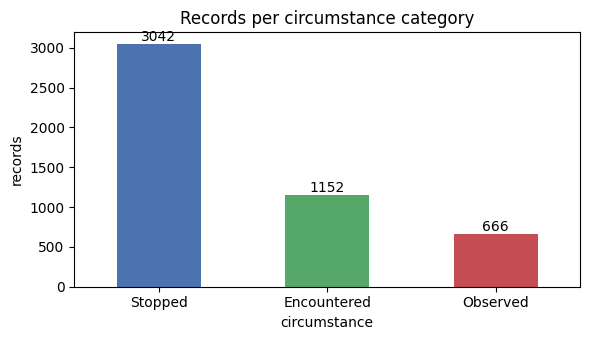

In [5]:
counts = df_raw[TARGET_COL].value_counts().reindex(LABELS)
display(pd.DataFrame({"records": counts, "share_%": (counts / counts.sum() * 100).round(1)}))

ax = counts.plot.bar(color=["#4C72B0", "#55A868", "#C44E52"], rot=0, figsize=(6, 3.5))
ax.set_title("Records per circumstance category"); ax.set_ylabel("records")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/class_distribution.png", dpi=150); plt.show()

### 1.4 Narrative length

,count,mean,std,min,25%,50%,75%,max
circumstance,,,,,,,,
Stopped,3042.0,114.3,72.6,0.0,66.0,97.0,142.0,1065.0
Encountered,1152.0,103.5,69.1,7.0,62.0,89.0,128.0,1070.0
Observed,666.0,98.2,64.7,2.0,56.0,84.5,125.0,550.0


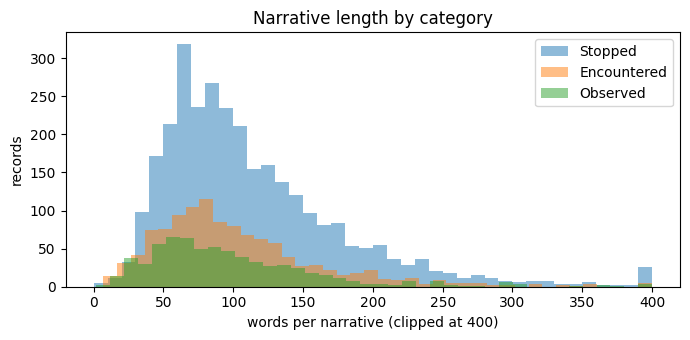

Narratives over 380 words (likely to exceed BERT's 512 tokens): 36


In [6]:
df_raw["n_words"] = df_raw[TEXT_COL].fillna("").str.split().str.len()
display(df_raw.groupby(TARGET_COL)["n_words"].describe().reindex(LABELS).round(1))

fig, ax = plt.subplots(figsize=(7, 3.5))
for lab in LABELS:
    ax.hist(df_raw.loc[df_raw[TARGET_COL] == lab, "n_words"].clip(upper=400), bins=40, alpha=0.5, label=lab)
ax.set_xlabel("words per narrative (clipped at 400)"); ax.set_ylabel("records"); ax.legend()
ax.set_title("Narrative length by category")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/length_distribution.png", dpi=150); plt.show()

print(f"Narratives over 380 words (likely to exceed BERT's 512 tokens): {(df_raw.n_words > 380).sum()}")

### 1.5 Leakage checks
Two risks are checked before any modelling:
1. **Label words in the text** – officers may write "stopped" or "observed" in the narrative.
2. **Other columns tied to the label** – e.g. `basis` (legal basis for the contact).

In [7]:
keywords = {"stop": r"\bstop", "encounter": r"\bencount", "observe": r"\bobserv",
            "frisk": r"\bfrisk", "traffic": r"\btraffic", "vehicle": r"\bvehicle"}
low = df_raw[TEXT_COL].fillna("").str.lower()
kw = pd.DataFrame({k: low.str.contains(p, regex=True) for k, p in keywords.items()})
kw[TARGET_COL] = df_raw[TARGET_COL]
kw_rates = (kw.groupby(TARGET_COL).mean() * 100).round(1).reindex(LABELS)
print("% of narratives in each category containing the keyword:")
display(kw_rates)

% of narratives in each category containing the keyword:


,stop,encounter,observe,frisk,traffic,vehicle
circumstance,,,,,,
Stopped,62.6,7.3,49.5,29.5,19.5,43.3
Encountered,13.9,33.3,43.1,6.5,4.6,16.5
Observed,14.7,6.3,83.9,2.0,8.1,38.6


In [8]:
basis_tab = pd.crosstab(df_raw["basis"].fillna("Missing"), df_raw[TARGET_COL])[LABELS]
display(basis_tab)
print("`basis` is strongly associated with the label (e.g. Probable Cause -> Stopped),")
print("so only the narrative text is used as model input.")

circumstance,Stopped,Encountered,Observed
basis,,,
Encounter,156,530,167
Intel,217,305,392
Missing,5,1,6
Probable Cause,1462,121,26
Reasonable Suspicion,1202,195,75


`basis` is strongly associated with the label (e.g. Probable Cause -> Stopped),
so only the narrative text is used as model input.


### 1.6 Cleaning
* keep only `fc_num`, the narrative and the label
* drop empty narratives
* drop repeated narratives **before** splitting, so identical texts cannot appear in both train and test
* normalise the source's own masks: the data publisher replaced names with `XXX`, often glued to the next word
  (`XXXwas`, `observedXXX`, `XX/XX/XXXX`). These become a separate `[REDACTED]` token so the real words survive
* normalise whitespace

In [9]:
df = df_raw[["fc_num", TEXT_COL, TARGET_COL]].copy()
MASK_RX = re.compile(r"X{2,}(?:\s*[/\-]\s*X{2,})*")
df[TEXT_COL] = (df[TEXT_COL].fillna("")
                .str.replace(MASK_RX, " [REDACTED] ", regex=True)
                .str.replace(r"(?:\[REDACTED\]\s*){2,}", "[REDACTED] ", regex=True)
                .str.replace(r"\s+", " ", regex=True).str.strip())

n0 = len(df)
df = df[df[TEXT_COL] != ""]
n_empty = n0 - len(df)

conflicts = df.groupby(TEXT_COL)[TARGET_COL].nunique().gt(1).sum()
n1 = len(df)
df = df.drop_duplicates(subset=TEXT_COL, keep="first").reset_index(drop=True)
n_dup = n1 - len(df)

print(f"Removed {n_empty} empty and {n_dup} duplicate narratives "
      f"({conflicts} duplicates had conflicting labels). Remaining: {len(df)}")
display(df[TARGET_COL].value_counts().reindex(LABELS).to_frame("records after cleaning"))

Removed 3 empty and 241 duplicate narratives (1 duplicates had conflicting labels). Remaining: 4616


,records after cleaning
circumstance,
Stopped,2917
Encountered,1074
Observed,625


### 1.7 Privacy redaction
Names of the people involved are already masked by the publisher (now `[REDACTED]`). The narratives still contain
**officer names**, streets and neighbourhoods. Redaction runs in two passes:

1. **Rules first** (precise, checked against the data):
   * officer and supervisor names, taken from the dataset's own `contact_officer_name` / `supervisor_name` columns.
     Name words that also appear as ordinary lower-case words in the narratives (*white, hill, brown, long, mark…*)
     are excluded so descriptions are not erased. Removing officer names also prevents the model learning
     *which officer wrote the report* instead of *what happened*.
   * street addresses, Boston neighbourhood names and phone numbers.
2. **spaCy NER second** for remaining people and places, with a filter for its known false positives on police text
   (job titles such as *Det* or *Sgt*, offence words such as *Larceny* or *Assault*, "pat" in *pat frisk*,
   state codes such as *MA Reg*, and unit call signs such as *B102F*).

All names become `[PERSON]`; streets and areas become `[ADDRESS]` or `[PLACE]`. The redacted text is used for every model.

In [10]:
nlp = spacy.load("en_core_web_sm")

# ---- Pass 1: rules ---------------------------------------------------------------
# Officer / supervisor name words from the record columns
name_words = set()
for col in ["contact_officer_name", "supervisor_name"]:
    for v in df_raw[col].dropna().astype(str):
        for w in re.split(r"[,\s]+", v):
            w = w.strip(".").lower()
            if len(w) > 2:
                name_words.add(w)

# Words that are also ordinary vocabulary in the narratives (e.g. "white", "hill") are kept
lower_vocab = pd.Series(re.findall(r"\b[a-z][a-z'\-]+\b", " ".join(df[TEXT_COL]))).value_counts()
common_words = {w for w in name_words if lower_vocab.get(w, 0) >= 3}
officer_words = name_words - common_words
print(f"Officer/supervisor name words: {len(name_words)} (kept as ordinary words: {sorted(common_words)})")

CAP_WORD = re.compile(r"\b[A-Z][A-Za-z'\-]+\b")
NEIGHBOURHOODS = ("Allston|Brighton|Back Bay|Bay Village|Beacon Hill|Charlestown|Chinatown|Dorchester|Downtown|"
                  "East Boston|Fenway|Hyde Park|Jamaica Plain|Mattapan|Mission Hill|North End|Roslindale|Roxbury|"
                  "South Boston|South End|West End|West Roxbury|Leather District|Longwood")
STREET_TYPES = "St|Street|Ave|Avenue|Rd|Road|Blvd|Pl|Place|Sq|Square|Ter|Terrace|Way|Ct|Court|Dr|Drive|Pk|Park|Hwy"
RULES = [
    ("[ADDRESS]", re.compile(rf"\b(?:\d{{1,5}}\s+)?(?:[A-Z][a-z]+\s){{1,3}}(?:{STREET_TYPES})\b\.?")),
    ("[PLACE]",   re.compile(rf"\b(?:{NEIGHBOURHOODS})\b", re.I)),
    ("[PHONE]",   re.compile(r"\b\(?\d{3}\)?[-. ]?\d{3}[-. ]\d{4}\b")),
]

redaction_counts = {"officer names": 0, "[ADDRESS]": 0, "[PLACE] rules": 0, "[PHONE]": 0,
                    "[PERSON] spaCy": 0, "[PLACE] spaCy": 0}

def redact_rules(text):
    def officer(m):
        if m.group(0).lower() in officer_words:
            redaction_counts["officer names"] += 1
            return "[PERSON]"
        return m.group(0)
    text = CAP_WORD.sub(officer, text)
    for tag, rx in RULES:
        text, n = rx.subn(tag, text)
        redaction_counts[tag if tag != "[PLACE]" else "[PLACE] rules"] += n
    return text

# ---- Pass 2: spaCy NER with a false-positive filter --------------------------------
ENT_TAGS = {"PERSON": "[PERSON]", "GPE": "[PLACE]", "LOC": "[PLACE]", "FAC": "[PLACE]"}
DOMAIN_TERMS = {
    "officer", "officers", "det", "detective", "sgt", "sergeant", "lt", "capt", "po", "trooper", "pat", "frisk",
    "driver", "operator", "passenger", "vehicle", "victim", "suspect", "subject", "larceny", "assault", "poss",
    "possession", "robbery", "rape", "warrant", "firearm", "gun", "drug", "drugs", "trespass", "shooting", "bwc",
    "activated", "reg", "bolo", "cjis", "intel", "safety", "gang", "fio", "ma", "us", "bb",
    "redacted", "person", "place", "address", "phone",
    "marijuana", "escape", "larcenies", "burglary", "premises", "ordinance", "district", "detectives",
    "mark", "breaking", "entering", "trafficking", "distribution", "unit", "dispatch",
}
UNIT_CODE = re.compile(r"^[A-Z]{1,2}\d{2,3}[A-Z]$")

def is_false_positive(ent):
    words = {w.lower().strip(".'") for w in ent.text.split()}
    return (bool(words & DOMAIN_TERMS) or bool(UNIT_CODE.match(ent.text)) or "[" in ent.text
            or any(ch.isdigit() for ch in ent.text))          # district / system codes such as "District B3"

skipped = Counter()

def redact_ner(doc):
    text, out, last = doc.text, [], 0
    for ent in doc.ents:
        if ent.label_ not in ENT_TAGS:
            continue
        if is_false_positive(ent):
            skipped[ent.text] += 1
            continue
        out.append(text[last:ent.start_char]); out.append(ENT_TAGS[ent.label_])
        redaction_counts["[PERSON] spaCy" if ent.label_ == "PERSON" else "[PLACE] spaCy"] += 1
        last = ent.end_char
    out.append(text[last:])
    return "".join(out)

rule_texts = [redact_rules(t) for t in df[TEXT_COL]]
docs = list(nlp.pipe(rule_texts, batch_size=64, disable=["parser"]))
df["text_redacted"] = [redact_ner(d) for d in docs]

print("Redactions made:", redaction_counts)
print("Narratives changed by redaction:", (df.text_redacted != df[TEXT_COL]).sum(), "of", len(df))
print("spaCy entities kept because they are police/legal terms (top 15):", skipped.most_common(15))

Officer/supervisor name words: 1050 (kept as ordinary words: ['ball', 'bang', 'beard', 'bent', 'brown', 'green', 'hill', 'holder', 'jean', 'king', 'long', 'mark', 'van', 'white', 'woods'])
Redactions made: {'officer names': 8883, '[ADDRESS]': 8197, '[PLACE] rules': 1398, '[PHONE]': 0, '[PERSON] spaCy': 1112, '[PLACE] spaCy': 1991}
Narratives changed by redaction: 4454 of 4616
spaCy entities kept because they are police/legal terms (top 15): [('Officers', 199), ('Det', 176), ('MA', 165), ('MA Reg', 145), ('Pat', 79), ('Larceny', 59), ('Assault', 54), ('Sgt', 53), ('Driver', 48), ('PO', 47), ('MA REG', 42), ('Ma Reg', 40), ('Vehicle', 39), ('BWC Activated', 39), ('B102F', 38)]


#### 1.7a Redaction check
What spaCy still replaces, and three redacted examples. Review these before training; report the counts in the
privacy section of the report.

In [11]:
for label in ["PERSON", "GPE", "LOC", "FAC"]:
    c = Counter(e.text for d in docs for e in d.ents if e.label_ == label and not is_false_positive(e))
    print(f"{label} redacted – {sum(c.values())} total, top 15: {c.most_common(15)}")

print()
for t in df.sample(3, random_state=SEED).text_redacted:
    print("-", t[:300], "\n")

PERSON redacted – 1112 total, top 15: [('Cass', 22), ('Melnea Cass', 18), ('Rob', 12), ('Lynn', 11), ('Walgreens', 11), ('Nissan Altima', 10), ('Morton', 10), ('Milaiko', 10), ('Evelyn', 9), ('Garfield', 9), ('Ellsworth', 9), ('Brown', 8), ('Caller', 8), ('grey hoodie', 7), ('Everett', 7)]
GPE redacted – 1526 total, top 15: [('Boston', 444), ('Massachusetts', 76), ('Washington', 52), ('Cambridge', 35), ('Brockton', 26), ('Florida', 23), ('Tremont', 22), ('Somerville', 19), ('Lenox', 18), ('South Station', 15), ('New Hampshire', 14), ('New York', 13), ('Albany', 13), ('St.', 12), ('Apt', 11)]
LOC redacted – 178 total, top 15: [('Battery', 13), ('Mt. Pleasant', 11), ('South Bay', 9), ('South', 7), ('the South Bay Mall', 7), ('Franklin Field', 5), ('Magnolia', 4), ('North Face', 4), ('Liberty Plaza', 3), ('Bunker Hill', 3), ('South Bay Mall', 3), ('West Broadway', 3), ('Park', 3), ('Weymouth', 3), ('Fall River', 3)]
FAC redacted – 287 total, top 15: [('Suffolk Superior', 25), ('Franklin F

### 1.8 Linguistic preprocessing for the TF-IDF baseline
BERT receives the redacted text as written (its own tokenizer handles casing and sub-words).
The traditional baseline gets a normalised version: lower-case lemmas with stop words, punctuation and numbers removed.
Negations are kept because they change meaning ("did not stop").

A second, **masked** version removes the label keywords (*stop*, *encounter*, *observe*) and is used as an
ablation to measure how much each model relies on them.

In [12]:
KEEP = {"no", "not", "nor", "never", "n't"}
PLACEHOLDERS = {"redacted", "place", "address", "person", "phone"}   # tags added during redaction
LABEL_WORDS = re.compile(r"\b(?:stop\w*|encount\w*|observ\w*)\b", flags=re.I)

redacted_docs = list(nlp.pipe(df.text_redacted, batch_size=64, disable=["parser", "ner"]))

def to_lemmas(doc):
    return " ".join(t.lemma_.lower() for t in doc
                    if not t.is_punct and not t.is_space and not t.like_num
                    and t.lower_ not in PLACEHOLDERS
                    and (not t.is_stop or t.lower_ in KEEP))

df["text_tfidf"] = [to_lemmas(d) for d in redacted_docs]
df["text_redacted_masked"] = df.text_redacted.str.replace(LABEL_WORDS, "[MASK]", regex=True)
df["text_tfidf_masked"] = df.text_tfidf.str.replace(LABEL_WORDS, " ", regex=True).str.split().str.join(" ")

display(df.sample(3, random_state=SEED)[["text_redacted", "text_tfidf", TARGET_COL]])

,text_redacted,text_tfidf,circumstance
2264,VICTIM [REDACTED] STATED THAT THIS WAS THE SUSPECT VEHICLE THAT STRUCK AND KILLED HER DOG,victim state suspect vehicle strike kill dog,Stopped
1839,Officers conducted a subject stop of 3 juvenile males smoking marijuana in the front vestibule of [REDACTED] [ADDRESS] As Officers approached Officers observed [REDACTED] run in a full sprint towa...,officer conduct subject stop juvenile male smoke marijuana vestibule officer approach officer observe run sprint apartment inside building officer speak male identify attempt provide officer false...,Stopped
2525,"About 5:46pm, Officers spoke with [REDACTED] (DOB [REDACTED] at [ADDRESS] & [ADDRESS], [PLACE]. Officers are aware that [REDACTED] was issued a stay-away order following his arraignment for a drug...",5:46pm officer speak dob officer aware issue stay away order follow arraignment drug arrest 05/14/24 docket company know dob officer know frequently involve drug sale use bwc activate ak15f person...,Encountered


#### 1.8a Bias check: the word "white"
"white" is one of the strongest baseline features for *Observed*. It may describe a vehicle, clothing or a person's
race. If it is mostly race, the model is partly using a demographic descriptor – an ethics finding for the report.

In [13]:
w = df[df.text_redacted.str.contains(r"\bwhite\b", case=False)]
print(f"Narratives containing 'white': {len(w)} of {len(df)}")
display(pd.DataFrame({"with 'white' (%)": (w[TARGET_COL].value_counts(normalize=True) * 100).round(1),
                      "all narratives (%)": (df[TARGET_COL].value_counts(normalize=True) * 100).round(1)}).reindex(LABELS))

# what follows "white" – nouns like male/female suggest race, car/jacket suggest description
nxt = w.text_redacted.str.lower().str.extractall(r"\bwhite\s+([a-z]+)")[0].value_counts().head(20)
display(nxt.to_frame("word after 'white'"))

Narratives containing 'white': 601 of 4616


,with 'white' (%),all narratives (%)
circumstance,,
Stopped,65.4,63.2
Encountered,19.0,23.3
Observed,15.6,13.5


,word after 'white'
0,
male,129
sneakers,59
female,40
t,26
honda,26
and,23
shirt,17
nike,16
nissan,15


### 1.9 Train / validation / test split
Stratified 70 / 15 / 15 split so every set keeps the same class proportions.
The validation set is used for tuning; the test set is used once, for final reporting.
The same split files are reused for BERT, so the comparison is fair.

In [14]:
df["label"] = df[TARGET_COL].map({l: i for i, l in enumerate(LABELS)})

train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df.label, random_state=SEED)
val_df, test_df   = train_test_split(temp_df, test_size=0.50, stratify=temp_df.label, random_state=SEED)

split_summary = pd.DataFrame({name: d[TARGET_COL].value_counts().reindex(LABELS)
                              for name, d in [("train", train_df), ("val", val_df), ("test", test_df)]})
split_summary.loc["total"] = split_summary.sum()
display(split_summary)

assert not set(train_df[TEXT_COL]) & set(test_df[TEXT_COL]), "text overlap between train and test"

KEEP_COLS = ["fc_num", "text_redacted", "text_redacted_masked", "text_tfidf", "text_tfidf_masked", TARGET_COL, "label"]
for name, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    d[KEEP_COLS].to_csv(f"{OUT_DIR}/{name}.csv", index=False)
print("Saved outputs/train.csv, outputs/val.csv, outputs/test.csv")

,train,val,test
circumstance,,,
Stopped,2042,437,438
Encountered,752,161,161
Observed,437,94,94
total,3231,692,693


Saved outputs/train.csv, outputs/val.csv, outputs/test.csv


## Phase 2 – Baseline: TF-IDF + Logistic Regression
Word uni-grams and bi-grams are weighted with TF-IDF. Logistic Regression uses `class_weight="balanced"` to offset
the smaller *Observed* class. The regularisation strength `C` is chosen on the validation set by macro F1,
which treats all three classes equally.

In [15]:
def evaluate(y_true, y_pred, name):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    return {"model": name, "accuracy": accuracy_score(y_true, y_pred),
            "macro_precision": p, "macro_recall": r, "macro_f1": f}

def train_tfidf_lr(text_col, name, Cs=(0.1, 0.3, 1, 3, 10)):
    best = None
    for C in Cs:
        vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.9, sublinear_tf=True)
        clf = LogisticRegression(C=C, class_weight="balanced", max_iter=3000, random_state=SEED)
        clf.fit(vec.fit_transform(train_df[text_col]), train_df.label)
        f = f1_score(val_df.label, clf.predict(vec.transform(val_df[text_col])), average="macro")
        if best is None or f > best[0]:
            best = (f, C, vec, clf)
    f_val, C, vec, clf = best
    pred = clf.predict(vec.transform(test_df[text_col]))
    res = evaluate(test_df.label, pred, name) | {"best_C": C, "val_macro_f1": f_val}
    return res, vec, clf, pred

base_res, base_vec, base_clf, base_pred = train_tfidf_lr("text_tfidf", "TF-IDF + LR")
mask_res, mask_vec, mask_clf, mask_pred = train_tfidf_lr("text_tfidf_masked", "TF-IDF + LR (label words masked)")

results = pd.DataFrame([base_res, mask_res]).set_index("model").round(3)
display(results)

,accuracy,macro_precision,macro_recall,macro_f1,best_C,val_macro_f1
model,,,,,,
TF-IDF + LR,0.775,0.707,0.682,0.693,10,0.738
TF-IDF + LR (label words masked),0.736,0.655,0.627,0.639,10,0.680


              precision    recall  f1-score   support

     Stopped      0.847     0.884     0.865       438
 Encountered      0.632     0.609     0.620       161
    Observed      0.642     0.553     0.594        94

    accuracy                          0.775       693
   macro avg      0.707     0.682     0.693       693
weighted avg      0.769     0.775     0.771       693



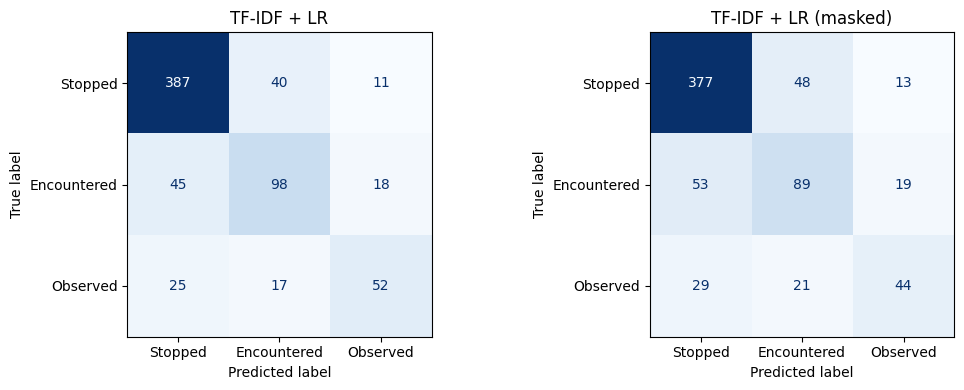

In [16]:
print(classification_report(test_df.label, base_pred, target_names=LABELS, digits=3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, pred, title in [(axes[0], base_pred, "TF-IDF + LR"), (axes[1], mask_pred, "TF-IDF + LR (masked)")]:
    ConfusionMatrixDisplay(confusion_matrix(test_df.label, pred), display_labels=LABELS).plot(
        ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(title)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/baseline_confusion.png", dpi=150); plt.show()

### 2.1 What the baseline learned
The highest-weighted n-grams per class show which phrases drive each prediction – an early, simple form of
explainability to compare later with BERT explanations.

In [17]:
feat = np.array(base_vec.get_feature_names_out())
top = pd.DataFrame({LABELS[i]: feat[np.argsort(base_clf.coef_[i])[::-1][:15]] for i in range(len(LABELS))})
display(top)

,Stopped,Encountered,Observed
0,stop,encounter,observe
1,officer stop,officer encounter,intel
2,release,conversation,officer observe
3,frisk,casual,observe dob
4,warning,state,area
5,operator,stop inform,observe area
6,val,know,generate
7,passenger,officer state,intel d101f
8,identify,personal,fio intel
9,arrest,interaction,recently


### 2.2 Save baseline results

In [18]:
results.to_csv(f"{OUT_DIR}/baseline_results.csv")
with open(f"{OUT_DIR}/data_prep_summary.json", "w") as fh:
    json.dump({"raw_rows": int(len(df_raw)), "after_cleaning": int(len(df)),
               "removed_empty": int(n_empty), "removed_duplicates": int(n_dup),
               "redactions": redaction_counts,
               "split": split_summary.drop("total").to_dict()}, fh, indent=2)
print("Saved baseline results and data-preparation summary to outputs/")

Saved baseline results and data-preparation summary to outputs/


## Findings – Phases 1 & 2 (Colab run, 17 Oct 2026)
* **Data cleaning:** 4,860 records → 4,616 after removing 3 empty and 241 duplicate narratives (1 duplicate group had
  conflicting labels). Split 70/15/15: 3,231 train, 692 validation, 693 test.
* **Class balance:** Stopped 63.2% (2,917), Encountered 23.3% (1,074), Observed 13.5% (625). Macro F1 is the main
  metric; a majority-class predictor would reach 63% accuracy but only ≈0.26 macro F1.
* **Redaction:** 8,883 officer-name mentions, 8,197 street addresses, 1,398 neighbourhood names, plus 1,112 names and
  1,991 places found by spaCy; 4,454 of 4,616 narratives were changed. Police and legal terms that spaCy mislabels as
  names (Det, Sgt, Pat, Larceny, MA Reg, unit codes) were kept.
* **Baseline (TF-IDF + LR, test set):** accuracy 0.775, macro F1 0.693. Per-class F1: Stopped 0.865,
  Encountered 0.620, Observed 0.594.
* **Label-word leakage:** masking *stop / encounter / observe* lowers macro F1 from 0.693 to 0.639 (−5.4 points). The
  keywords help, but most of the signal comes from context (frisk, warning, operator, passenger → Stopped;
  conversation, casual, interaction → Encountered; intel, area, unknown → Observed).
* **Hardest class:** Observed (recall 0.553) – confused with both other classes.
* **Bias signal:** "white" is a top-15 Observed feature. It appears in 601 narratives, mostly describing clothing
  and vehicles, but about 170 times as a racial descriptor ("white male" 129, "white female" 40). Narratives containing
  it are slightly more often Observed (15.6% vs 13.5%).
* **Next step:** Phase 3 – fine-tune BERT on the same split and test whether context reduces the
  Encountered/Observed confusion.

## Phase 3 – Fine-tuning BERT
**Needs a GPU runtime:** Runtime → Change runtime type → T4 GPU, then Run all.
Phase 3 takes roughly 20–25 minutes on a T4 (3 seeds × 2 text versions).

Set-up, chosen to make the comparison with the baseline fair and robust:
* `bert-base-uncased` with a 3-class classification head, trained on the **same** train / validation / test split
* input = the redacted narrative as written (`text_redacted`); BERT's WordPiece tokenizer handles casing and sub-words
* **class-weighted cross-entropy** to offset the small *Observed* class (same idea as `class_weight="balanced"` in Phase 2)
* AdamW, learning rate 2e-5, 10% warm-up then linear decay, 4 epochs, mixed precision
* the epoch with the best **validation** macro F1 is kept; the test set is used once, at the end
* **3 random seeds**, reported as mean ± standard deviation, because fine-tuning on ~3,200 examples varies between runs
* the same **label-word-masked ablation** as the baseline

In [19]:
import time, shutil
import torch
from torch.utils.data import Dataset, DataLoader
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          DataCollatorWithPadding, get_linear_schedule_with_warmup)
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU – switch to a GPU runtime before training")

MODEL_NAME = "bert-base-uncased"
MAX_LEN = 320          # tokens; checked in the next cell
BATCH_SIZE = 16
EPOCHS = 4
LR = 2e-5
SEEDS = [42, 43, 44]
RUN_MASKED_ABLATION = True
BERT_DIR = f"{OUT_DIR}/bert_best"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

Device: Tesla T4


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

### 3.1 Sequence length
BERT reads at most 512 tokens. A shorter limit trains faster; this checks how many narratives it would cut off.

In [20]:
tok_lens = np.array([len(ids) for ids in tokenizer(train_df.text_redacted.tolist())["input_ids"]])
print("Tokens per narrative – median:", int(np.median(tok_lens)),
      "| 90th pct:", int(np.percentile(tok_lens, 90)), "| 95th pct:", int(np.percentile(tok_lens, 95)),
      "| max:", tok_lens.max())
print(f"Narratives longer than MAX_LEN={MAX_LEN}: {(tok_lens > MAX_LEN).mean():.1%} (only their end is cut off)")

Tokens per narrative – median: 160 | 90th pct: 298 | 95th pct: 362 | max: 1716
Narratives longer than MAX_LEN=320: 7.7% (only their end is cut off)


### 3.2 Data loading, class weights and the training loop

In [21]:
class NarrativeDataset(Dataset):
    def __init__(self, texts, labels):
        self.enc = tokenizer(list(texts), truncation=True, max_length=MAX_LEN)
        self.labels = [int(l) for l in labels]
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, i):
        item = {k: self.enc[k][i] for k in self.enc}
        item["labels"] = self.labels[i]
        return item

collator = DataCollatorWithPadding(tokenizer)      # pads each batch only to its longest narrative

counts = np.bincount(train_df.label, minlength=len(LABELS))
class_weights = torch.tensor(len(train_df) / (len(LABELS) * counts), dtype=torch.float)
print("Class weights:", dict(zip(LABELS, class_weights.numpy().round(2))))

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

USE_AMP = device.type == "cuda"

@torch.no_grad()
def predict(model, loader):
    model.eval()
    probs = []
    for batch in loader:
        batch = {k: v.to(device) for k, v in batch.items()}
        batch.pop("labels")
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
            logits = model(**batch).logits
        probs.append(torch.softmax(logits.float(), dim=-1).cpu())
    probs = torch.cat(probs).numpy()
    return probs.argmax(1), probs

def train_bert(text_col, seed, name):
    set_seed(seed)
    g = torch.Generator(); g.manual_seed(seed)
    train_dl = DataLoader(NarrativeDataset(train_df[text_col], train_df.label), batch_size=BATCH_SIZE,
                          shuffle=True, collate_fn=collator, generator=g)
    val_dl  = DataLoader(NarrativeDataset(val_df[text_col],  val_df.label),  batch_size=64, collate_fn=collator)
    test_dl = DataLoader(NarrativeDataset(test_df[text_col], test_df.label), batch_size=64, collate_fn=collator)

    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=len(LABELS),
        id2label=dict(enumerate(LABELS)), label2id={l: i for i, l in enumerate(LABELS)}).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
    total_steps = len(train_dl) * EPOCHS
    scheduler = get_linear_schedule_with_warmup(optimizer, int(0.1 * total_steps), total_steps)
    loss_fn = torch.nn.CrossEntropyLoss(weight=class_weights.to(device))
    scaler = torch.amp.GradScaler(enabled=USE_AMP)

    best = {"f1": -1}
    history = []
    for epoch in range(1, EPOCHS + 1):
        model.train(); t0 = time.time(); running = 0.0
        for batch in train_dl:
            batch = {k: v.to(device) for k, v in batch.items()}
            labels = batch.pop("labels")
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
                logits = model(**batch).logits
            loss = loss_fn(logits.float(), labels)
            optimizer.zero_grad()
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer); scaler.update(); scheduler.step()
            running += loss.item()
        val_pred, _ = predict(model, val_dl)
        val_f1 = f1_score(val_df.label, val_pred, average="macro")
        history.append({"model": name, "seed": seed, "epoch": epoch,
                        "train_loss": running / len(train_dl), "val_macro_f1": val_f1})
        print(f"  {name} seed {seed} | epoch {epoch} | loss {running / len(train_dl):.4f} "
              f"| val macro F1 {val_f1:.3f} | {time.time() - t0:.0f}s")
        if val_f1 > best["f1"]:
            best = {"f1": val_f1, "epoch": epoch,
                    "state": {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}}

    model.load_state_dict(best["state"])
    test_pred, test_prob = predict(model, test_dl)
    res = evaluate(test_df.label, test_pred, name) | {"seed": seed, "best_epoch": best["epoch"],
                                                      "val_macro_f1": best["f1"]}
    return res, model, test_pred, test_prob, history

Class weights: {'Stopped': np.float32(0.53), 'Encountered': np.float32(1.43), 'Observed': np.float32(2.46)}


### 3.3 Train BERT (3 seeds)
The run with the best **validation** macro F1 is saved to `outputs/bert_best` for the explainability step and the
Streamlit app.

In [22]:
bert_runs, bert_history, bert_preds = [], [], {}
best_val = -1
for seed in SEEDS:
    res, model, pred, prob, hist = train_bert("text_redacted", seed, "BERT")
    bert_runs.append(res); bert_history += hist; bert_preds[seed] = (pred, prob)
    if res["val_macro_f1"] > best_val:
        best_val, best_seed = res["val_macro_f1"], seed
        model.save_pretrained(BERT_DIR); tokenizer.save_pretrained(BERT_DIR)
    del model; torch.cuda.empty_cache()
    print(f"Seed {seed}: test macro F1 {res['macro_f1']:.3f}, accuracy {res['accuracy']:.3f}\n")

print(f"Best validation run: seed {best_seed} – saved to {BERT_DIR}")

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

  BERT seed 42 | epoch 1 | loss 0.9700 | val macro F1 0.746 | 51s
  BERT seed 42 | epoch 2 | loss 0.6206 | val macro F1 0.748 | 53s
  BERT seed 42 | epoch 3 | loss 0.4662 | val macro F1 0.778 | 54s
  BERT seed 42 | epoch 4 | loss 0.3524 | val macro F1 0.763 | 54s


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

  BERT seed 43 | epoch 1 | loss 0.9804 | val macro F1 0.748 | 54s
  BERT seed 43 | epoch 2 | loss 0.6374 | val macro F1 0.782 | 53s
  BERT seed 43 | epoch 3 | loss 0.4809 | val macro F1 0.752 | 53s
  BERT seed 43 | epoch 4 | loss 0.3684 | val macro F1 0.755 | 54s


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Seed 43: test macro F1 0.734, accuracy 0.795



Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

  BERT seed 44 | epoch 1 | loss 0.9498 | val macro F1 0.749 | 52s
  BERT seed 44 | epoch 2 | loss 0.6385 | val macro F1 0.761 | 52s
  BERT seed 44 | epoch 3 | loss 0.4815 | val macro F1 0.769 | 52s
  BERT seed 44 | epoch 4 | loss 0.3684 | val macro F1 0.770 | 53s
Seed 44: test macro F1 0.745, accuracy 0.804

Best validation run: seed 43 – saved to outputs/bert_best


### 3.4 Ablation: BERT with the label words masked

In [23]:
if RUN_MASKED_ABLATION:
    for seed in SEEDS:
        res, model, _, _, hist = train_bert("text_redacted_masked", seed, "BERT (label words masked)")
        bert_runs.append(res); bert_history += hist
        del model; torch.cuda.empty_cache()
        print(f"Seed {seed}: test macro F1 {res['macro_f1']:.3f}\n")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

  BERT (label words masked) seed 42 | epoch 1 | loss 0.9651 | val macro F1 0.679 | 52s
  BERT (label words masked) seed 42 | epoch 2 | loss 0.6722 | val macro F1 0.709 | 52s
  BERT (label words masked) seed 42 | epoch 3 | loss 0.5082 | val macro F1 0.725 | 52s
  BERT (label words masked) seed 42 | epoch 4 | loss 0.3791 | val macro F1 0.730 | 52s
Seed 42: test macro F1 0.703



Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

  BERT (label words masked) seed 43 | epoch 1 | loss 1.0088 | val macro F1 0.637 | 52s
  BERT (label words masked) seed 43 | epoch 2 | loss 0.7058 | val macro F1 0.710 | 52s
  BERT (label words masked) seed 43 | epoch 3 | loss 0.5382 | val macro F1 0.672 | 53s
  BERT (label words masked) seed 43 | epoch 4 | loss 0.4224 | val macro F1 0.700 | 53s
Seed 43: test macro F1 0.687



Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

  BERT (label words masked) seed 44 | epoch 1 | loss 0.9875 | val macro F1 0.623 | 52s
  BERT (label words masked) seed 44 | epoch 2 | loss 0.7391 | val macro F1 0.695 | 52s
  BERT (label words masked) seed 44 | epoch 3 | loss 0.5593 | val macro F1 0.716 | 52s
  BERT (label words masked) seed 44 | epoch 4 | loss 0.4235 | val macro F1 0.714 | 52s
Seed 44: test macro F1 0.689



## Phase 4 – Model comparison
### 4.1 Overall results
BERT is reported as mean ± standard deviation over the 3 seeds; the baseline is deterministic.

In [24]:
runs = pd.DataFrame(bert_runs)
metrics = ["accuracy", "macro_precision", "macro_recall", "macro_f1"]

def summarise(name, df_runs):
    row = {"model": name, "runs": len(df_runs)}
    for m in metrics:
        row[m] = f"{df_runs[m].mean():.3f} ± {df_runs[m].std(ddof=1):.3f}" if len(df_runs) > 1 else f"{df_runs[m].iloc[0]:.3f}"
    return row

comparison = pd.DataFrame(
    [summarise("TF-IDF + LR", pd.DataFrame([base_res])),
     summarise("TF-IDF + LR (label words masked)", pd.DataFrame([mask_res])),
     summarise("BERT", runs[runs.model == "BERT"])]
    + ([summarise("BERT (label words masked)", runs[runs.model == "BERT (label words masked)"])]
       if RUN_MASKED_ABLATION else [])
).set_index("model")
display(comparison)

runs.to_csv(f"{OUT_DIR}/bert_runs.csv", index=False)
pd.DataFrame(bert_history).to_csv(f"{OUT_DIR}/bert_training_history.csv", index=False)
comparison.to_csv(f"{OUT_DIR}/model_comparison.csv")

,runs,accuracy,macro_precision,macro_recall,macro_f1
model,,,,,
TF-IDF + LR,1,0.775,0.707,0.682,0.693
TF-IDF + LR (label words masked),1,0.736,0.655,0.627,0.639
BERT,3,0.794 ± 0.011,0.747 ± 0.032,0.729 ± 0.013,0.732 ± 0.014
BERT (label words masked),3,0.759 ± 0.010,0.723 ± 0.011,0.680 ± 0.010,0.693 ± 0.008


### 4.2 Training curves

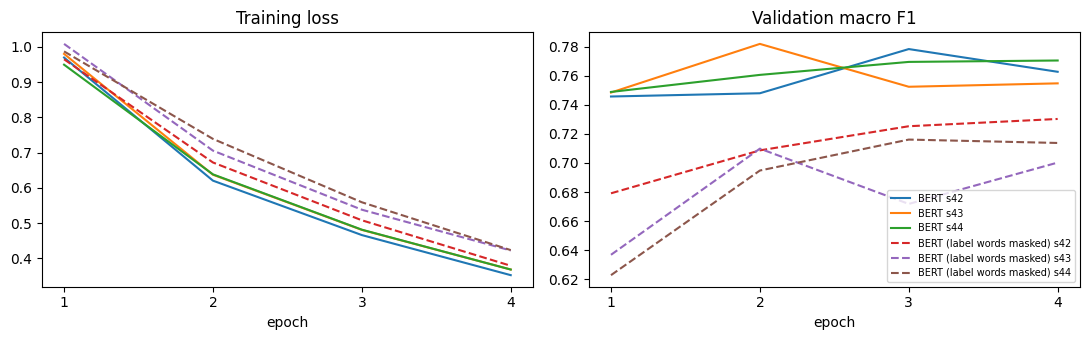

In [25]:
hist = pd.DataFrame(bert_history)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for (name, seed), h in hist.groupby(["model", "seed"]):
    style = "-" if name == "BERT" else "--"
    axes[0].plot(h.epoch, h.train_loss, style, label=f"{name} s{seed}")
    axes[1].plot(h.epoch, h.val_macro_f1, style, label=f"{name} s{seed}")
axes[0].set_title("Training loss"); axes[1].set_title("Validation macro F1")
for ax in axes:
    ax.set_xlabel("epoch"); ax.set_xticks(range(1, EPOCHS + 1))
axes[1].legend(fontsize=7)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/bert_training_curves.png", dpi=150); plt.show()

### 4.3 Per-class results and confusion matrices
Uses the BERT run with the best validation score (the saved model).

              precision    recall  f1-score   support

     Stopped      0.881     0.863     0.872       438
 Encountered      0.598     0.758     0.668       161
    Observed      0.850     0.543     0.662        94

    accuracy                          0.795       693
   macro avg      0.776     0.721     0.734       693
weighted avg      0.811     0.795     0.796       693



,TF-IDF + LR F1,BERT F1,change,TF-IDF + LR recall,BERT recall
Stopped,0.865,0.872,0.007,0.884,0.863
Encountered,0.620,0.668,0.048,0.609,0.758
Observed,0.594,0.662,0.068,0.553,0.543


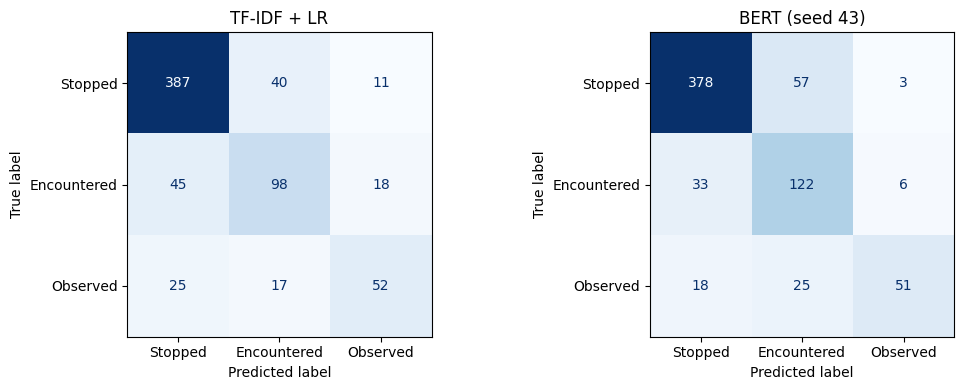

In [26]:
bert_pred, bert_prob = bert_preds[best_seed]
print(classification_report(test_df.label, bert_pred, target_names=LABELS, digits=3))

p_b, r_b, f_b, _ = precision_recall_fscore_support(test_df.label, base_pred, labels=range(3), zero_division=0)
p_t, r_t, f_t, _ = precision_recall_fscore_support(test_df.label, bert_pred, labels=range(3), zero_division=0)
display(pd.DataFrame({"TF-IDF + LR F1": f_b, "BERT F1": f_t, "change": f_t - f_b,
                      "TF-IDF + LR recall": r_b, "BERT recall": r_t}, index=LABELS).round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, pred, title in [(axes[0], base_pred, "TF-IDF + LR"), (axes[1], bert_pred, f"BERT (seed {best_seed})")]:
    ConfusionMatrixDisplay(confusion_matrix(test_df.label, pred), display_labels=LABELS).plot(
        ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(title)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/comparison_confusion.png", dpi=150); plt.show()

### 4.4 Is the difference significant?
McNemar's test compares the two models on the same test narratives: it looks only at cases where exactly one model
is right. A p-value below 0.05 means the difference is unlikely to be chance.

In [27]:
from scipy.stats import binomtest
y = test_df.label.values
base_ok, bert_ok = base_pred == y, bert_pred == y
only_bert, only_base = int((bert_ok & ~base_ok).sum()), int((base_ok & ~bert_ok).sum())
p_value = binomtest(only_bert, only_bert + only_base, 0.5).pvalue
print(f"Only BERT correct: {only_bert} | only TF-IDF + LR correct: {only_base} | exact McNemar p = {p_value:.4f}")

Only BERT correct: 52 | only TF-IDF + LR correct: 38 | exact McNemar p = 0.1702


### 4.5 Error analysis
BERT's most confident mistakes – the narratives worth reading for the report. Texts are redacted.

In [28]:
errors = test_df[["fc_num", "text_redacted", TARGET_COL]].copy()
errors["bert_pred"] = [LABELS[i] for i in bert_pred]
errors["bert_confidence"] = bert_prob.max(1).round(3)
errors["baseline_pred"] = [LABELS[i] for i in base_pred]
errors = errors[errors.bert_pred != errors[TARGET_COL]].sort_values("bert_confidence", ascending=False)

print(f"BERT errors: {len(errors)} of {len(test_df)}")
display(pd.crosstab(errors[TARGET_COL], errors.bert_pred, rownames=["true"], colnames=["BERT predicted"]))
for _, r in errors.head(6).iterrows():
    print(f"\n[true {r[TARGET_COL]} → BERT {r.bert_pred} ({r.bert_confidence}), baseline {r.baseline_pred}]")
    print(r.text_redacted[:400])

errors.to_csv(f"{OUT_DIR}/bert_errors.csv", index=False)
pd.DataFrame({"fc_num": test_df.fc_num, "true": test_df[TARGET_COL],
              "baseline_pred": [LABELS[i] for i in base_pred], "bert_pred": [LABELS[i] for i in bert_pred],
              **{f"p_{l}": bert_prob[:, i] for i, l in enumerate(LABELS)}}
             ).to_csv(f"{OUT_DIR}/test_predictions.csv", index=False)

BERT errors: 142 of 693


BERT predicted,Encountered,Observed,Stopped
true,,,
Encountered,0,6,33
Observed,25,0,18
Stopped,57,3,0



[true Encountered → BERT Stopped (0.9449999928474426), baseline Stopped]
Traffic stop for VALS (failure to use turn signal) at [REDACTED] [ADDRESS] CT Reg [REDACTED] , black Toyota Corrola Operator was [REDACTED] , active [REDACTED] prior F/As and Possession to distribute A and B Front passenger, [REDACTED] , active [REDACTED] prior vehicle homicide, F/As, and trafficking. Both [REDACTED] and [REDACTED] were cordial with officers. Mr. [REDACTED] license currently suspe

[true Encountered → BERT Stopped (0.9340000152587891), baseline Stopped]
TS for Vals (Speeding 90:17) on a black Mazda 3 (Ma Reg# [REDACTED] Operator identified as [REDACTED] (Open Home Invasion, F/A, 94C). [REDACTED] originally confrontational during stop. [REDACTED] stated he currently uses his girlfriend's car and resides at [REDACTED] [ADDRESS] FIO to association [REDACTED] with M/V/ Verbal warning issued for Vals. C113 ([PERSON] / [PERSON])

[true Encountered → BERT Stopped (0.9279999732971191), baseline Stopped]


### 4.6 Keep the results
Colab deletes `outputs/` when the session ends. Download the folder, or set `SAVE_TO_DRIVE = True` to copy it
(including the ~420 MB model) to Google Drive.

In [29]:
SAVE_TO_DRIVE = False

results_only = [f for f in os.listdir(OUT_DIR) if f != "bert_best"]
import zipfile
with zipfile.ZipFile("results_without_model.zip", "w") as z:
    for f in results_only:
        z.write(os.path.join(OUT_DIR, f), f)
print("Created results_without_model.zip (charts, CSVs) – download it from the Files panel.")

if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    dest = "/content/drive/MyDrive/Police_Narrative_Project/outputs"
    shutil.copytree(OUT_DIR, dest, dirs_exist_ok=True)
    print("Copied outputs/ to", dest)

Created results_without_model.zip (charts, CSVs) – download it from the Files panel.


## Findings – Phases 3 & 4 (Colab T4 run, 19 Oct 2026)
* **BERT vs baseline:** BERT reaches macro F1 0.732 ± 0.014 (3 seeds: 0.716 / 0.734 / 0.745) against 0.693 for
  TF-IDF + LR – a gain of +3.9 points, and every seed beats the baseline. Accuracy rises from 0.775 to 0.794 ± 0.011.
* **Significance:** on the best-validation run (seed 43), BERT is right on 52 narratives where the baseline is wrong,
  and the baseline on 38 where BERT is wrong. McNemar p = 0.17, so on a 693-narrative test set the improvement is
  consistent but not statistically significant at the 5% level.
* **Where BERT helps:** the gains are in the minority classes. Encountered F1 rises 0.620 → 0.668 (recall
  0.609 → 0.758) and Observed F1 rises 0.594 → 0.662, driven by much higher precision (0.850); Observed recall is
  unchanged (0.543). Stopped is almost the same (0.865 → 0.872).
* **Masked ablation:** removing *stop / encounter / observe* costs BERT 3.9 points (0.732 → 0.693) and the baseline
  5.4 points (0.693 → 0.639). BERT without the label words matches the baseline with them, so it extracts more
  signal from context, although it still uses the keywords.
* **Training:** loss falls steadily; validation macro F1 peaks at epoch 2–3, and keeping the best epoch avoids
  overfitting. Masked runs vary less between seeds (sd 0.008).
* **Errors:** 142 of 693 test narratives are misclassified. The largest confusion is Stopped → Encountered (57),
  then Encountered → Stopped (33) and Observed → Encountered (25). Observed is still the hardest class: 43 of 94
  are missed.
* **Label inconsistency:** BERT's most confident errors are narratives labelled *Encountered* whose text describes
  a stop ("Traffic stop for VALS…", "Officers stopped…", "Subject stop of…"); 13.9% of Encountered narratives
  contain "stop". The category in the record does not always match what the officer wrote, so part of the
  remaining error is label noise rather than model failure, and it caps achievable accuracy.
* **Limitation:** 7.7% of narratives exceed 320 tokens and lose their ending.